# Fig. 3 — Treatment trade-offs between tumor reduction and leader suppression
Each curve follows one single-entry perturbation ($R_x\alpha$, $R_x\beta$, $R_x\gamma$, $R_x\delta$) as the dose $d$ increases from 0 to 1.
x-axis: population reduction $R_N(T)$; y-axis: leader suppression $S_L(T)=1-x(T)$. A–D: $T=15$ days, E–H: $T=30$ days.
$N(0)=10^5$, $x(0)=0.5$, $K=10^{10}$, α = 0.4, δ = 0.6.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lf_model import *
set_style()

In [2]:
d = np.linspace(0, 1, 201)
out = {}
for T in (15.0, 30.0):
    for name, (b, g) in REGIMES.items():
        for tg in TARGETS:
            out[T, name, tg] = treatment_outcome(b, g, {tg: d}, T=T)

# numbers quoted in the text (T = 15): best single-agent dose and J per regime
for name, (b, g) in REGIMES.items():
    x_u, _ = simulate(ALPHA, b, g, DELTA, T=15)
    print(f"{name}: untreated S_L = {1 - x_u:.3f}")
    for tg in TARGETS:
        r_n, s_l, J, _ = out[15.0, name, tg]
        i = int(np.argmax(J))
        print(f"   {tg:5s} best d = {d[i]:.2f}: R_N = {r_n[i]:5.1f}%, S_L = {s_l[i]:.3f}, J = {J[i]:.3f}"
              f"   | d = 1: R_N = {r_n[-1]:5.1f}%, S_L = {s_l[-1]:.3f}")

Snowdrift: untreated S_L = 0.646
   alpha best d = 1.00: R_N =  37.0%, S_L = 0.784, J = 0.577   | d = 1: R_N =  37.0%, S_L = 0.784
   beta  best d = 1.00: R_N =  71.2%, S_L = 1.000, J = 0.856   | d = 1: R_N =  71.2%, S_L = 1.000
   gamma best d = 0.41: R_N =  79.2%, S_L = 0.353, J = 0.572   | d = 1: R_N =  97.4%, S_L = 0.004
   delta best d = 1.00: R_N =  84.1%, S_L = 0.336, J = 0.589   | d = 1: R_N =  84.1%, S_L = 0.336
Harmony: untreated S_L = 0.048
   alpha best d = 1.00: R_N =  47.3%, S_L = 0.500, J = 0.487   | d = 1: R_N =  47.3%, S_L = 0.500
   beta  best d = 0.58: R_N =  34.5%, S_L = 0.776, J = 0.561   | d = 1: R_N = -132.1%, S_L = 0.999
   gamma best d = 1.00: R_N =  40.8%, S_L = 0.004, J = 0.206   | d = 1: R_N =  40.8%, S_L = 0.004
   delta best d = 1.00: R_N =  42.0%, S_L = 0.015, J = 0.218   | d = 1: R_N =  42.0%, S_L = 0.015
Coordination: untreated S_L = 0.981
   alpha best d = 0.00: R_N =   0.0%, S_L = 0.981, J = 0.490   | d = 1: R_N = -71.1%, S_L = 0.996
   beta  best d =

Saved ../figures/Fig3_single_treatment_tradeoffs.png/.pdf


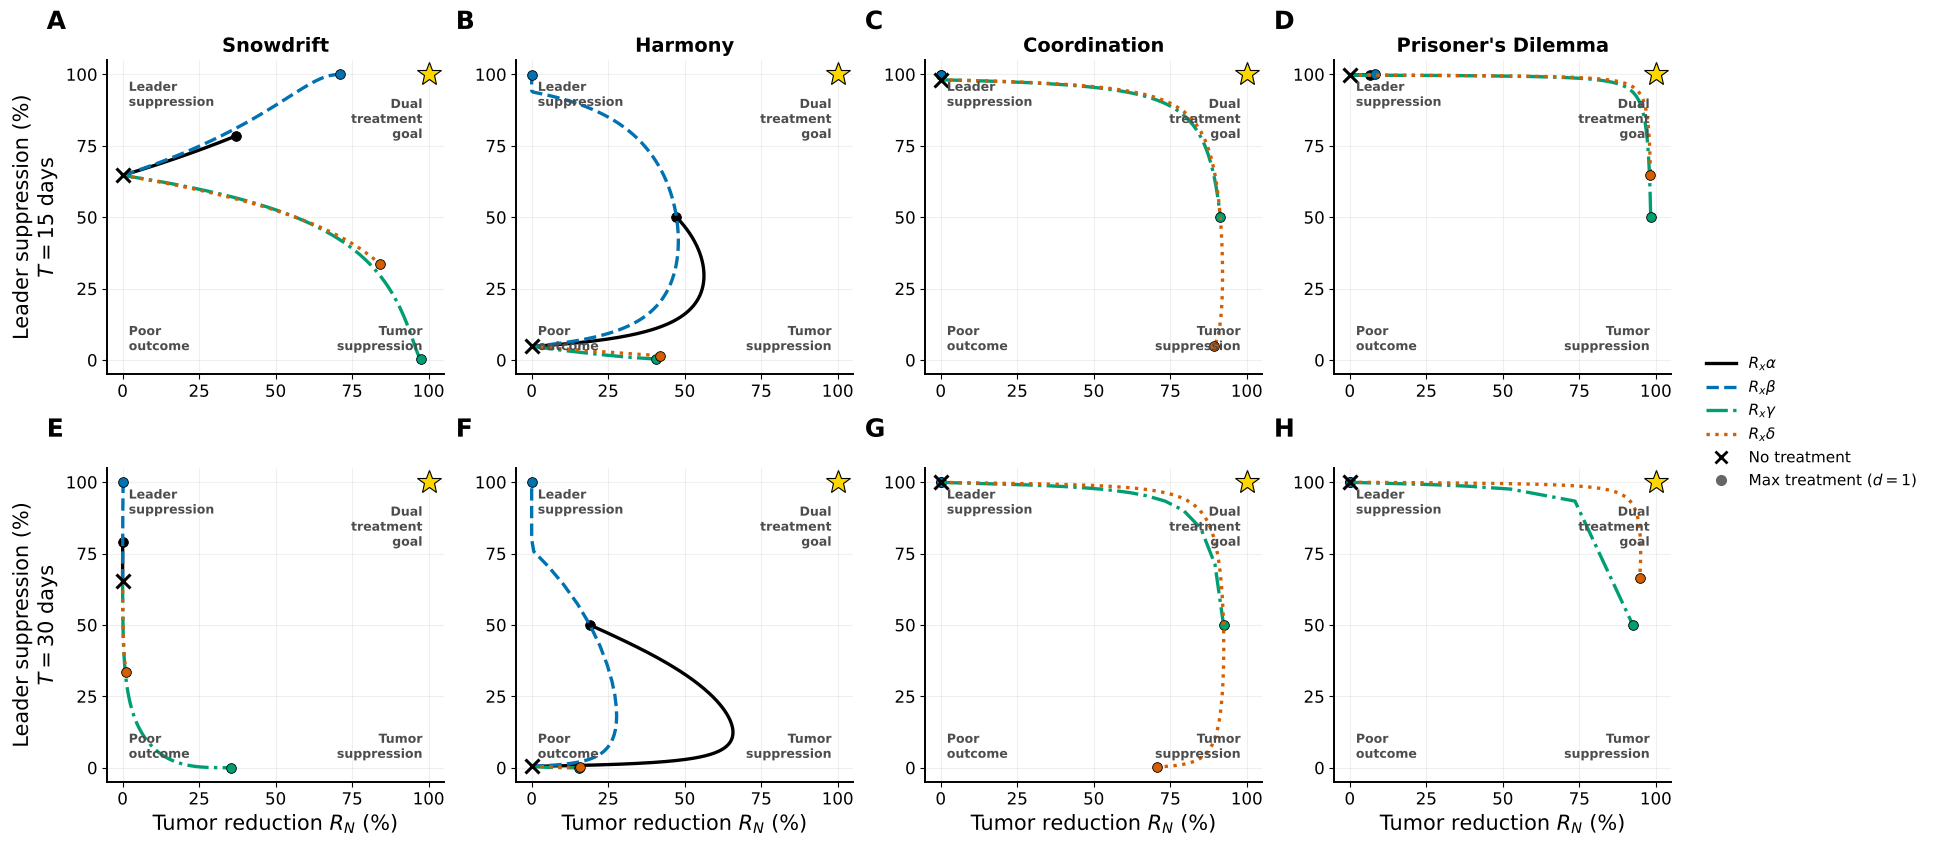

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(17, 8.6))
letters = "ABCDEFGH"
for row, T in enumerate((15.0, 30.0)):
    for j, name in enumerate(REGIME_ORDER):
        ax = axes[row, j]
        for tg in TARGETS:
            r_n, s_l, J, _ = out[T, name, tg]
            r_n = np.clip(r_n, 0, 100)          # negative R_N (treatment increases growth) shown as 0, as in the paper
            ax.plot(r_n, 100 * s_l, TARGET_STYLE[tg], color=TARGET_COLOR[tg], lw=2.4, label=TARGET_LABEL[tg])
            ax.plot(r_n[-1], 100 * s_l[-1], "o", color=TARGET_COLOR[tg], ms=7, mec="k", mew=0.6)
        ax.plot(0, 100 * out[T, name, "alpha"][1][0], "kx", ms=10, mew=2.2)
        ax.plot(100, 100, "*", color="gold", ms=18, mec="k", mew=0.8)
        for (xx, yy, txt, ha, va) in [(2, 98, "Leader\nsuppression", "left", "top"),
                                      (98, 92, "Dual\ntreatment\ngoal", "right", "top"),
                                      (2, 2, "Poor\noutcome", "left", "bottom"),
                                      (98, 2, "Tumor\nsuppression", "right", "bottom")]:
            ax.text(xx, yy, txt, ha=ha, va=va, fontsize=9, fontweight="bold", color="0.3")
        ax.set_xlim(-5, 105); ax.set_ylim(-5, 105)
        ax.set_xticks([0, 25, 50, 75, 100]); ax.set_yticks([0, 25, 50, 75, 100])
        ax.grid(alpha=0.2)
        if row == 0:
            ax.set_title(name, fontweight="bold")
        if row == 1:
            ax.set_xlabel("Tumor reduction $R_N$ (%)")
        if j == 0:
            ax.set_ylabel(f"Leader suppression (%)\n$T={T:.0f}$ days")
        panel_letter(ax, letters[4 * row + j])
handles = [plt.Line2D([], [], color=TARGET_COLOR[tg], ls=TARGET_STYLE[tg], lw=2.4, label=TARGET_LABEL[tg]) for tg in TARGETS]
handles += [plt.Line2D([], [], color="k", marker="x", ls="none", ms=9, mew=2, label="No treatment"),
            plt.Line2D([], [], color="0.4", marker="o", ls="none", ms=7, label="Max treatment ($d=1$)")]
fig.legend(handles=handles, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
fig.tight_layout()
save(fig, "Fig3_single_treatment_tradeoffs")
plt.show()